# Task 1 — Download and load the dataset

## Upload the dataset

In [24]:

# Task 01: Download and Load the Dataset

import pandas as pd
import numpy as np
import re
from collections import Counter

from google.colab import files

uploaded = files.upload()


Saving imdb_labelled.txt to imdb_labelled (1).txt


## Read and inspect the dataset

In [26]:

# Load the IMDB labelled sentences dataset

df = pd.read_csv(
    "imdb_labelled.txt",
    sep="\t",
    header=None,
    names=["sentence", "label"]
)

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df["label"].value_counts().sort_index())

display(df.head())


Dataset shape: (748, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sentence  748 non-null    object
 1   label     748 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 11.8+ KB

Missing values:
sentence    0
label       0
dtype: int64

Sentiment distribution:
label
0    362
1    386
Name: count, dtype: int64


,sentence,label
0,"A very, very, very slow-moving, aimless movie ...",0
1,Not sure who was more lost - the flat characte...,0
2,Attempting artiness with black & white and cle...,0
3,Very little music or anything to speak of.,0
4,The best scene in the movie was when Gerardo i...,1


# Task 2 — Basic text preprocessing

## Validate and clean the data

In [27]:
# Task 02: Basic Text Preprocessing

# Remove rows with missing sentences or labels
df = df.dropna(subset=["sentence", "label"]).copy()

# Ensure labels are numeric and retain only binary labels 0 and 1
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["label"]).copy()
df = df[df["label"].isin([0, 1])].copy()
df["label"] = df["label"].astype(int)

# Text preprocessing function
def process_text(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Remove punctuation, numbers, and unnecessary characters
    # Replace them with spaces to avoid joining separate words
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Create a cleaned text column
df["clean_text"] = df["sentence"].apply(process_text)

print("Preprocessing completed.")

# Compare original and cleaned text
display(df[["sentence", "clean_text", "label"]].head(10))


Preprocessing completed.


,sentence,clean_text,label
0,"A very, very, very slow-moving, aimless movie ...",a very very very slow moving aimless movie abo...,0
1,Not sure who was more lost - the flat characte...,not sure who was more lost the flat characters...,0
2,Attempting artiness with black & white and cle...,attempting artiness with black white and cleve...,0
3,Very little music or anything to speak of.,very little music or anything to speak of,0
4,The best scene in the movie was when Gerardo i...,the best scene in the movie was when gerardo i...,1
5,"The rest of the movie lacks art, charm, meanin...",the rest of the movie lacks art charm meaning ...,0
6,Wasted two hours.,wasted two hours,0
7,Saw the movie today and thought it was a good ...,saw the movie today and thought it was a good ...,1
8,A bit predictable.,a bit predictable,0
9,Loved the casting of Jimmy Buffet as the scien...,loved the casting of jimmy buffet as the scien...,1


# Task 3 — Explore the text data

## Display positive and negative examples

In [28]:

# Task 03: Explore the Text Data

print("POSITIVE SENTENCES (label = 1):")

display(
    df.loc[df["label"] == 1, ["sentence", "clean_text"]].head(5)
)

print("\nNEGATIVE SENTENCES (label = 0):")

display(
    df.loc[df["label"] == 0, ["sentence", "clean_text"]].head(5)
)


POSITIVE SENTENCES (label = 1):


,sentence,clean_text
4,The best scene in the movie was when Gerardo i...,the best scene in the movie was when gerardo i...
7,Saw the movie today and thought it was a good ...,saw the movie today and thought it was a good ...
9,Loved the casting of Jimmy Buffet as the scien...,loved the casting of jimmy buffet as the scien...
10,And those baby owls were adorable.,and those baby owls were adorable
11,The movie showed a lot of Florida at it's best...,the movie showed a lot of florida at it s best...



NEGATIVE SENTENCES (label = 0):


,sentence,clean_text
0,"A very, very, very slow-moving, aimless movie ...",a very very very slow moving aimless movie abo...
1,Not sure who was more lost - the flat characte...,not sure who was more lost the flat characters...
2,Attempting artiness with black & white and cle...,attempting artiness with black white and cleve...
3,Very little music or anything to speak of.,very little music or anything to speak of
5,"The rest of the movie lacks art, charm, meanin...",the rest of the movie lacks art charm meaning ...


## Identify frequently occurring words

In [12]:
# Identify frequently occurring words¶
# Combine all cleaned text
all_words = " ".join(df["clean_text"]).split()

# Count word frequencies
word_counts = Counter(all_words)

print("\nMost Common Words Overall:")
print(word_counts.most_common(30))


Most Common Words Overall:
[('the', 844), ('a', 431), ('and', 430), ('of', 375), ('is', 340), ('this', 290), ('i', 267), ('it', 252), ('to', 251), ('in', 203), ('was', 185), ('movie', 177), ('that', 155), ('film', 155), ('for', 105), ('as', 94), ('but', 92), ('with', 90), ('its', 88), ('one', 77), ('on', 75), ('you', 75), ('are', 75), ('not', 73), ('bad', 67), ('very', 65), ('just', 63), ('so', 60), ('all', 60), ('good', 56)]


## Compare positive and negative word frequencies

In [30]:

# Compare frequently occurring words by sentiment

import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

# Retain important sentiment-related negation words
stop_words -= {"not", "no", "nor", "never"}

# Extract words from positive sentences
positive_words = " ".join(
    df.loc[df["label"] == 1, "clean_text"]
).split()

# Extract words from negative sentences
negative_words = " ".join(
    df.loc[df["label"] == 0, "clean_text"]
).split()

# Remove common English stop words
positive_words_clean = [
    word for word in positive_words
    if word not in stop_words
]

negative_words_clean = [
    word for word in negative_words
    if word not in stop_words
]

# Calculate word frequencies
positive_counts = Counter(positive_words_clean)
negative_counts = Counter(negative_words_clean)

print("Most Common Words in Positive Sentences:")
print(positive_counts.most_common(20))

print("\nMost Common Words in Negative Sentences:")
print(negative_counts.most_common(20))


Most Common Words in Positive Sentences:
[('film', 91), ('movie', 87), ('good', 36), ('one', 35), ('great', 29), ('really', 23), ('like', 23), ('well', 22), ('see', 22), ('not', 21), ('acting', 19), ('characters', 18), ('time', 17), ('wonderful', 17), ('best', 16), ('movies', 16), ('character', 16), ('also', 15), ('love', 15), ('funny', 14)]

Most Common Words in Negative Sentences:
[('movie', 95), ('film', 72), ('bad', 64), ('not', 52), ('one', 44), ('even', 33), ('time', 26), ('no', 25), ('like', 25), ('acting', 24), ('plot', 22), ('good', 22), ('would', 20), ('really', 18), ('characters', 17), ('make', 16), ('ever', 16), ('script', 16), ('much', 15), ('see', 14)]


# Task 4 — Split the dataset

## Create the train-test split

In [31]:

# Task 04: Split the Dataset

from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())


Total samples: 748
Training samples: 598
Testing samples: 150

Training label distribution:
label
1    309
0    289
Name: count, dtype: int64

Testing label distribution:
label
1    77
0    73
Name: count, dtype: int64


# Task 5 — Create Bag of Words (BOW) representation

## Convert text into BOW features

In [32]:

# Task 05: Create Bag of Words Representation

from sklearn.feature_extraction.text import CountVectorizer

# Create the BOW vectorizer
vectorizer = CountVectorizer(max_features=10000)

# Learn the vocabulary from training data
X_train_bow = vectorizer.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_bow = vectorizer.transform(X_test)

print("Training BOW shape:", X_train_bow.shape)
print("Testing BOW shape:", X_test_bow.shape)

print("\nSample vocabulary:")
print(list(vectorizer.vocabulary_.keys())[:20])


Training BOW shape: (598, 2611)
Testing BOW shape: (150, 2611)

Sample vocabulary:
['all', 'the', 'pretty', 'pictures', 'in', 'world', 'cannot', 'make', 'up', 'for', 'piece', 'of', 'work', 'that', 'is', 'flawed', 'at', 'core', 'too', 'politically']


## View the BOW representation

In [33]:

# Display BOW features for the first five training sentences

bow_df = pd.DataFrame(
    X_train_bow[:5].toarray(),
    columns=vectorizer.get_feature_names_out()
)

display(bow_df)


,abandoned,ability,about,above,abroad,absolutely,abstruse,abysmal,academy,accents,...,you,young,your,yourself,youthful,youtube,yun,zillion,zombie,zombiez
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Train a machine learning model

In [34]:

# Task 06: Train a Machine Learning Model

from sklearn.linear_model import LogisticRegression

# Initialize the classifier
model = LogisticRegression(max_iter=1000)

# Train the model using BOW features and sentiment labels
model.fit(X_train_bow, y_train)

print("Logistic Regression model training completed.")


Logistic Regression model training completed.


# Task 7 — Evaluate model performance

In [35]:

# Task 07: Evaluate Model Performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Predict labels for the test data
y_pred = model.predict(X_test_bow)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))


Model Evaluation Results
------------------------
Accuracy : 0.7133
Precision: 0.7125
Recall   : 0.7403
F1-score : 0.7261

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.68      0.70        73
    Positive       0.71      0.74      0.73        77

    accuracy                           0.71       150
   macro avg       0.71      0.71      0.71       150
weighted avg       0.71      0.71      0.71       150



## Display the confusion matrix

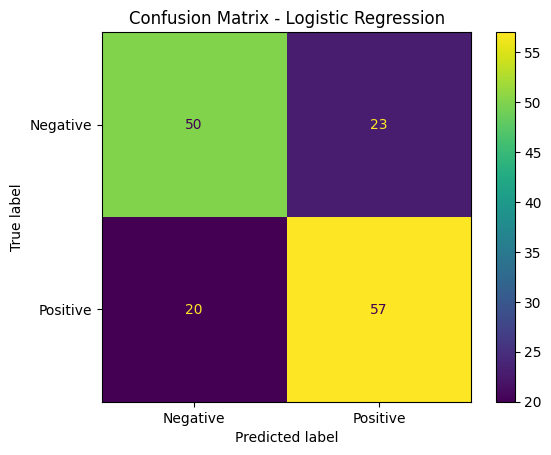

In [36]:

# Plot the confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


# Task 8 — Test the model with new sentences

## Predict the sentiment of new sentences

In [37]:

# Task 08: Test the Model with New Sentences

new_sentences = [
    "This movie was absolutely fantastic and enjoyable.",
    "The movie was boring and a complete waste of time.",
    "The acting was good but the story was terrible.",
    "I would never recommend this movie to anyone."
]

# Apply the same preprocessing used during training
new_clean_sentences = [
    process_text(sentence)
    for sentence in new_sentences
]

# Convert the new sentences into BOW features
new_sentences_bow = vectorizer.transform(new_clean_sentences)

# Predict sentiment labels
predictions = model.predict(new_sentences_bow)

# Get predicted probabilities for the positive class (label 1)
probabilities = model.predict_proba(new_sentences_bow)[:, 1]

# Display predictions
for sentence, prediction, probability in zip(
    new_sentences, predictions, probabilities
):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Original sentence:", sentence)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probability:.4f}")
    print("-" * 60)


Original sentence: This movie was absolutely fantastic and enjoyable.
Predicted sentiment: Positive
Positive probability: 0.6176
------------------------------------------------------------
Original sentence: The movie was boring and a complete waste of time.
Predicted sentiment: Negative
Positive probability: 0.2264
------------------------------------------------------------
Original sentence: The acting was good but the story was terrible.
Predicted sentiment: Negative
Positive probability: 0.4434
------------------------------------------------------------
Original sentence: I would never recommend this movie to anyone.
Predicted sentiment: Negative
Positive probability: 0.1228
------------------------------------------------------------
